# CNN Baseline vs HarmonicCNN — Detailed Comparison

**Task:** Multi-label instrument identification on IRMAS dataset  
**Models compared:**
- `InstrumentCNN` — baseline: 3-block CNN + GlobalAvgPool + MLP
- `HarmonicCNN` — domain-aware: stacks mel spectrogram shifted by 0/1/2/3 octaves as 4 channels, exploiting harmonic overtone structure

**Hypothesis:** HarmonicCNN should outperform the baseline on harmonic instruments (brass, woodwinds, bowed strings) where overtone structure is prominent.

In [1]:
import sys
sys.path.insert(0, 'src')

import random
import time
import json
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    accuracy_score, hamming_loss, roc_auc_score,
    classification_report,
)
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from dataset import CLASSES, NUM_CLASSES, IRMASDataset, load_training_dataset, train_val_split
from model import InstrumentCNN, HarmonicCNN

PROJECT_ROOT = Path('.')
TRAIN_ROOT   = PROJECT_ROOT / 'data' / 'IRMAS' / 'training'

BG, FG   = '#0f1117', '#e0e0e0'
BLUE     = '#4c8eff'
GREEN    = '#26c6a2'
ORANGE   = '#ffb74d'
RED      = '#e57373'
PURPLE   = '#ce93d8'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG, 'axes.edgecolor': FG,
    'axes.labelcolor': FG, 'xtick.color': FG, 'ytick.color': FG,
    'text.color': FG, 'grid.color': '#2a2a3a', 'grid.linestyle': '--',
    'font.size': 11,
})

FAMILIES = {
    'Bowed strings': ['cel', 'vio'],
    'Woodwinds':     ['cla', 'flu', 'sax'],
    'Brass':         ['tru'],
    'Plucked':       ['gac', 'gel'],
    'Keyboard':      ['org', 'pia'],
    'Voice':         ['voi'],
}
CLASS_TO_FAMILY = {c: f for f, cs in FAMILIES.items() for c in cs}

def get_device():
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')

device = get_device()
print(f'Device: {device}')

Device: mps


## 1. Load dataset

In [2]:
def find_training_root(base):
    if any((base / c).is_dir() for c in CLASSES):
        return base
    for child in sorted(base.iterdir()):
        if child.is_dir() and any((child / c).is_dir() for c in CLASSES):
            return child
    raise RuntimeError(f'Cannot find instrument folders under {base}')

train_root = find_training_root(TRAIN_ROOT)
full_ds    = load_training_dataset(train_root)
total      = len(full_ds)
print(f'Total samples : {total}')
print(f'Avg per class : {total // 11}')

# Fixed 80/20 stratified split — same for all seeds
train_paths, train_labels, val_paths, val_labels = train_val_split(
    full_ds.wav_paths, full_ds.labels, seed=42
)
train_ds = IRMASDataset(train_paths, train_labels)
val_ds   = IRMASDataset(val_paths,   val_labels)
print(f'Train: {len(train_ds)}  |  Val: {len(val_ds)}')

Total samples : 4388
Avg per class : 398
Train: 3510  |  Val: 878


## 2. Training helpers

In [3]:
# ── Config ────────────────────────────────────────────────────────────────────
EPOCHS     = 30
BATCH_SIZE = 32
LR         = 1e-3
THRESHOLD  = 0.3
N_SEEDS    = 5

CKPT_DIR = PROJECT_ROOT / 'checkpoints'
CKPT_DIR.mkdir(exist_ok=True)

def ckpt_path(model_name, seed):
    return CKPT_DIR / f'{model_name}_seed{seed}_ep{EPOCHS}.pt'

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)

def run_epoch(model, loader, criterion, optimizer, desc):
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    with torch.set_grad_enabled(training):
        for x, y in tqdm(loader, desc=desc, leave=False):
            x, y = x.to(device), y.to(device)
            loss = criterion(model(x), y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
    return total_loss / len(loader.dataset)

def evaluate(model, loader):
    model.eval()
    all_probs, all_targets = [], []
    with torch.no_grad():
        for x, y in loader:
            probs = torch.sigmoid(model(x.to(device))).cpu().numpy()
            all_probs.append(probs)
            all_targets.append(y.numpy().astype(int))
    probs   = np.vstack(all_probs)
    targets = np.vstack(all_targets)
    preds   = (probs >= THRESHOLD).astype(int)
    return {'probs': probs, 'preds': preds, 'targets': targets}

def compute_metrics(probs, preds, targets):
    return {
        'f1_macro':   f1_score(targets, preds, average='macro',  zero_division=0),
        'f1_micro':   f1_score(targets, preds, average='micro',  zero_division=0),
        'prec_macro': precision_score(targets, preds, average='macro',  zero_division=0),
        'prec_micro': precision_score(targets, preds, average='micro',  zero_division=0),
        'rec_macro':  recall_score(targets, preds, average='macro',  zero_division=0),
        'rec_micro':  recall_score(targets, preds, average='micro',  zero_division=0),
        'hamming_acc': 1 - hamming_loss(targets, preds),
        'subset_acc':  accuracy_score(targets, preds),
        'auc_macro':   roc_auc_score(targets, probs, average='macro'),
        'f1_per':      f1_score(targets, preds, average=None, zero_division=0),
        'prec_per':    precision_score(targets, preds, average=None, zero_division=0),
        'rec_per':     recall_score(targets, preds, average=None,  zero_division=0),
        'auc_per':     roc_auc_score(targets, probs, average=None),
        'acc_per':     np.array([(preds[:, k] == targets[:, k]).mean()
                                 for k in range(targets.shape[1])]),
    }

def train_model(model_cls, seed, desc=''):
    path = ckpt_path(model_cls.__name__, seed)

    # ── Load from checkpoint if available ────────────────────────────────────
    if path.exists():
        print(f'  [seed {seed}] Loading checkpoint: {path.name}')
        ckpt    = torch.load(path, map_location=device, weights_only=False)
        metrics = ckpt['metrics']
        metrics['history'] = ckpt['history']
        metrics['probs']   = ckpt['probs']
        metrics['targets'] = ckpt['targets']
        return metrics

    # ── Train from scratch ────────────────────────────────────────────────────
    set_seed(seed)
    model     = model_cls().to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
    val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

    history = {'train': [], 'val': []}
    for epoch in tqdm(range(1, EPOCHS + 1), desc=desc):
        tl = run_epoch(model, train_loader, criterion, optimizer, f'E{epoch} train')
        vl = run_epoch(model, val_loader,   criterion, None,      f'E{epoch} val')
        history['train'].append(tl)
        history['val'].append(vl)

    raw     = evaluate(model, val_loader)
    metrics = compute_metrics(raw['probs'], raw['preds'], raw['targets'])

    # ── Save checkpoint ───────────────────────────────────────────────────────
    torch.save({
        'model_state': model.state_dict(),
        'history':     history,
        'metrics':     metrics,
        'probs':       raw['probs'],
        'targets':     raw['targets'],
        'config':      {'epochs': EPOCHS, 'lr': LR, 'threshold': THRESHOLD},
    }, path)
    print(f'  [seed {seed}] Saved: {path.name}')

    metrics['history'] = history
    metrics['probs']   = raw['probs']
    metrics['targets'] = raw['targets']
    return metrics

def aggregate(all_metrics):
    def m(key): return np.mean([x[key] for x in all_metrics], axis=0)
    def s(key): return np.std( [x[key] for x in all_metrics], axis=0)
    scalar_keys = ['f1_macro','f1_micro','prec_macro','prec_micro',
                   'rec_macro','rec_micro','hamming_acc','subset_acc','auc_macro']
    result = {}
    for k in scalar_keys:
        result[k]          = float(m(k))
        result[f'{k}_std'] = float(s(k))
        result[f'{k}_all'] = [float(x[k]) for x in all_metrics]
    for k in ['f1_per','prec_per','rec_per','auc_per','acc_per']:
        result[k]          = m(k)
        result[f'{k}_std'] = s(k)
    result['histories']  = [x['history'] for x in all_metrics]
    result['mean_probs'] = np.mean([x['probs']   for x in all_metrics], axis=0)
    result['targets']    = all_metrics[0]['targets']
    return result

## 3. Train both models (N_SEEDS runs each)


In [4]:
print(f'Training CNN baseline  ({N_SEEDS} seeds × {EPOCHS} epochs) …')
cnn_runs  = [train_model(InstrumentCNN,  s, f'CNN  seed={s}') for s in range(N_SEEDS)]
cnn_r     = aggregate(cnn_runs)
print(f'  CNN  F1-macro: {cnn_r["f1_macro"]:.4f} ± {cnn_r["f1_macro_std"]:.4f}')

print(f'\nTraining HarmonicCNN  ({N_SEEDS} seeds × {EPOCHS} epochs) …')
harm_runs = [train_model(HarmonicCNN,    s, f'Harm seed={s}') for s in range(N_SEEDS)]
harm_r    = aggregate(harm_runs)
print(f'  Harm F1-macro: {harm_r["f1_macro"]:.4f} ± {harm_r["f1_macro_std"]:.4f}')

Training CNN baseline  (5 seeds × 30 epochs) …
  [seed 0] Loading checkpoint: InstrumentCNN_seed0_ep30.pt
  [seed 1] Loading checkpoint: InstrumentCNN_seed1_ep30.pt
  [seed 2] Loading checkpoint: InstrumentCNN_seed2_ep30.pt
  [seed 3] Loading checkpoint: InstrumentCNN_seed3_ep30.pt
  [seed 4] Loading checkpoint: InstrumentCNN_seed4_ep30.pt
  CNN  F1-macro: 0.6319 ± 0.0499

Training HarmonicCNN  (5 seeds × 30 epochs) …
  [seed 0] Loading checkpoint: HarmonicCNN_seed0_ep30.pt
  [seed 1] Loading checkpoint: HarmonicCNN_seed1_ep30.pt
  [seed 2] Loading checkpoint: HarmonicCNN_seed2_ep30.pt
  [seed 3] Loading checkpoint: HarmonicCNN_seed3_ep30.pt
  [seed 4] Loading checkpoint: HarmonicCNN_seed4_ep30.pt
  Harm F1-macro: 0.6841 ± 0.0181


## 4. Overall metrics comparison

In [5]:
n_cnn  = sum(p.numel() for p in InstrumentCNN().parameters() if p.requires_grad)
n_harm = sum(p.numel() for p in HarmonicCNN().parameters()   if p.requires_grad)

overall_metrics = [
    ("Subset Accuracy",  "subset_acc",  "exact match — всі 11 міток правильні"),
    ("Hamming Accuracy", "hamming_acc", "per-label accuracy (avg по всіх мітках)"),
    ("F1-macro",         "f1_macro",    "середнє F1 по класах"),
    ("F1-micro",         "f1_micro",    "F1 по всіх передбаченнях разом"),
    ("Precision-macro",  "prec_macro",  ""),
    ("Precision-micro",  "prec_micro",  ""),
    ("Recall-macro",     "rec_macro",   ""),
    ("Recall-micro",     "rec_micro",   ""),
    ("AUC-ROC macro",    "auc_macro",   "area under ROC curve"),
]

print(f'{"Metric":<20} {"CNN baseline":>18} {"HarmonicCNN":>18} {"Δ":>10}  {"Пояснення"}')
print("─" * 90)
for label, key, note in overall_metrics:
    cv, cs = cnn_r[key], cnn_r[f'{key}_std']
    hv, hs = harm_r[key], harm_r[f'{key}_std']
    d = hv - cv
    sign = "▲" if d > 0 else "▼"
    print(f'{label:<20} {cv:.4f}±{cs:.4f}   {hv:.4f}±{hs:.4f}   {sign}{abs(d):.4f}  {note}')

print(f'\n{"Parameters":<20} {n_cnn:>18,} {n_harm:>18,} {n_harm-n_cnn:>+10,}')

Metric                     CNN baseline        HarmonicCNN          Δ  Пояснення
──────────────────────────────────────────────────────────────────────────────────────────
Subset Accuracy      0.5267±0.0489   0.5752±0.0140   ▲0.0485  exact match — всі 11 міток правильні
Hamming Accuracy     0.9337±0.0083   0.9410±0.0028   ▲0.0073  per-label accuracy (avg по всіх мітках)
F1-macro             0.6319±0.0499   0.6841±0.0181   ▲0.0522  середнє F1 по класах
F1-micro             0.6382±0.0515   0.6825±0.0194   ▲0.0443  F1 по всіх передбаченнях разом
Precision-macro      0.6690±0.0173   0.6907±0.0125   ▲0.0217  
Precision-micro      0.6312±0.0434   0.6673±0.0137   ▲0.0361  
Recall-macro         0.6463±0.0623   0.6990±0.0321   ▲0.0528  
Recall-micro         0.6460±0.0621   0.6991±0.0319   ▲0.0531  
AUC-ROC macro        0.9361±0.0115   0.9451±0.0032   ▲0.0090  area under ROC curve

Parameters                      288,747            621,355   +332,608


## 5. Per-class full comparison table

In [6]:
## 6. Plot — Per-class heatmap (всі метрики разом)

In [7]:
## 7. Plot — AUC-ROC per class

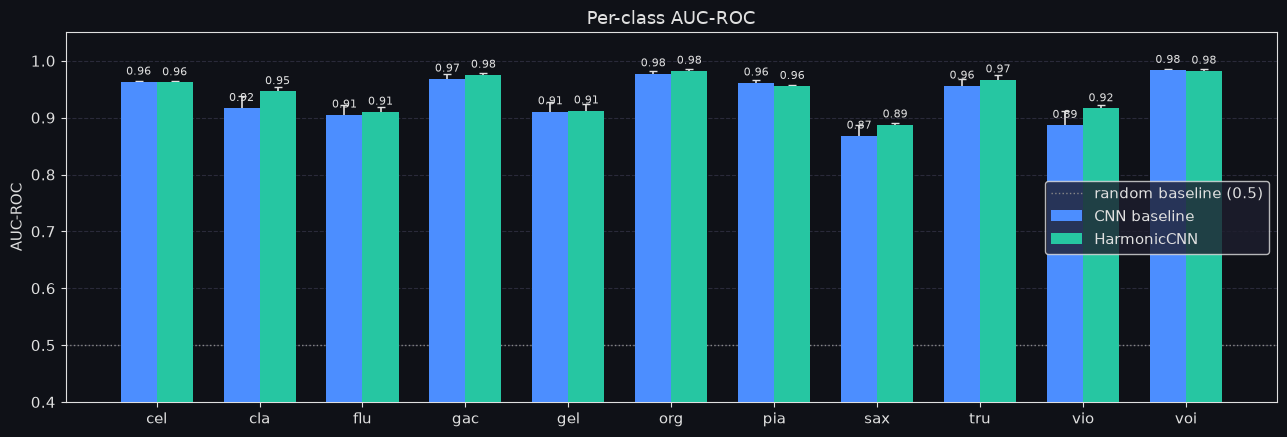

In [8]:
fig, ax = plt.subplots(figsize=(13, 4.5))
x = np.arange(len(CLASSES))
w = 0.35

b1 = ax.bar(x - w/2, cnn_r['auc_per'],  w, color=BLUE,  label='CNN baseline', zorder=3)
b2 = ax.bar(x + w/2, harm_r['auc_per'], w, color=GREEN, label='HarmonicCNN',   zorder=3)

if N_SEEDS > 1:
    ax.errorbar(x - w/2, cnn_r['auc_per'],  yerr=cnn_r['auc_per_std'],
                fmt='none', color=FG, capsize=3, lw=1.2)
    ax.errorbar(x + w/2, harm_r['auc_per'], yerr=harm_r['auc_per_std'],
                fmt='none', color=FG, capsize=3, lw=1.2)

for bar in list(b1) + list(b2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.008,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=8, color=FG)

ax.axhline(0.5, color='#888888', lw=1, linestyle=':', label='random baseline (0.5)')
ax.set_xticks(x)
ax.set_xticklabels(CLASSES)
ax.set_ylim(0.4, 1.05)
ax.set_ylabel('AUC-ROC')
ax.set_title('Per-class AUC-ROC', color=FG)
ax.legend(facecolor='#1e1e2e', edgecolor=FG)
ax.grid(axis='y', zorder=0)

plt.tight_layout()
plt.savefig('plots/harmonic_detail/h7_auc_per_class.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Plot — Training loss curves

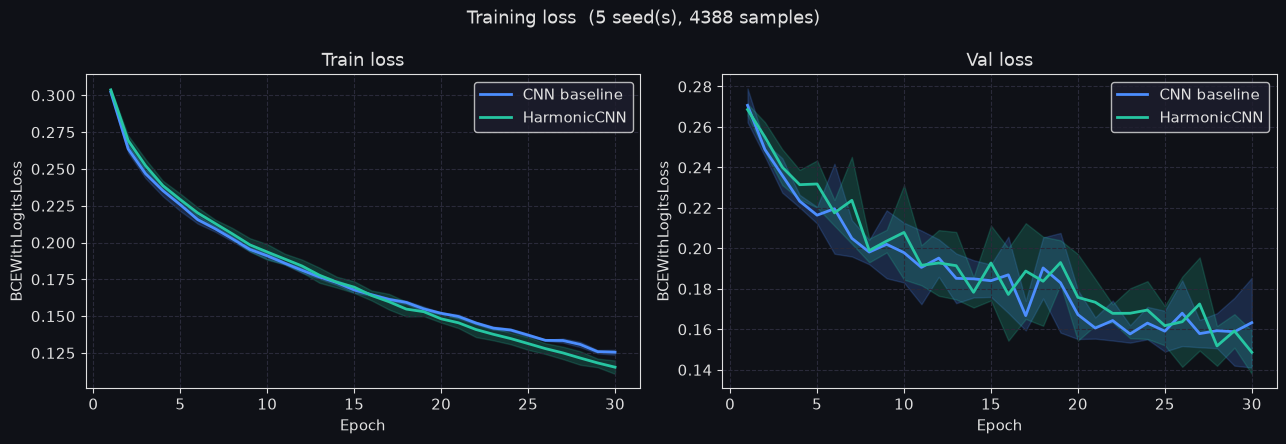

In [9]:
epochs = list(range(1, EPOCHS + 1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
fig.suptitle(f'Training loss  ({N_SEEDS} seed(s), {total} samples)', color=FG, fontsize=13)

for ax, split in zip(axes, ['train', 'val']):
    for r, col, label in [(cnn_r, BLUE, 'CNN baseline'), (harm_r, GREEN, 'HarmonicCNN')]:
        mat  = np.array([h[split] for h in r['histories']])
        mean = mat.mean(axis=0)
        std  = mat.std(axis=0)
        ax.plot(epochs, mean, color=col, lw=2, label=label)
        if N_SEEDS > 1:
            ax.fill_between(epochs, mean - std, mean + std, color=col, alpha=0.2)
    ax.set_title(f'{split.capitalize()} loss', color=FG)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('BCEWithLogitsLoss')
    ax.legend(facecolor='#1e1e2e', edgecolor=FG)
    ax.grid(True)

plt.tight_layout()
plt.savefig('plots/harmonic_detail/h1_loss_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Plot — Per-class F1

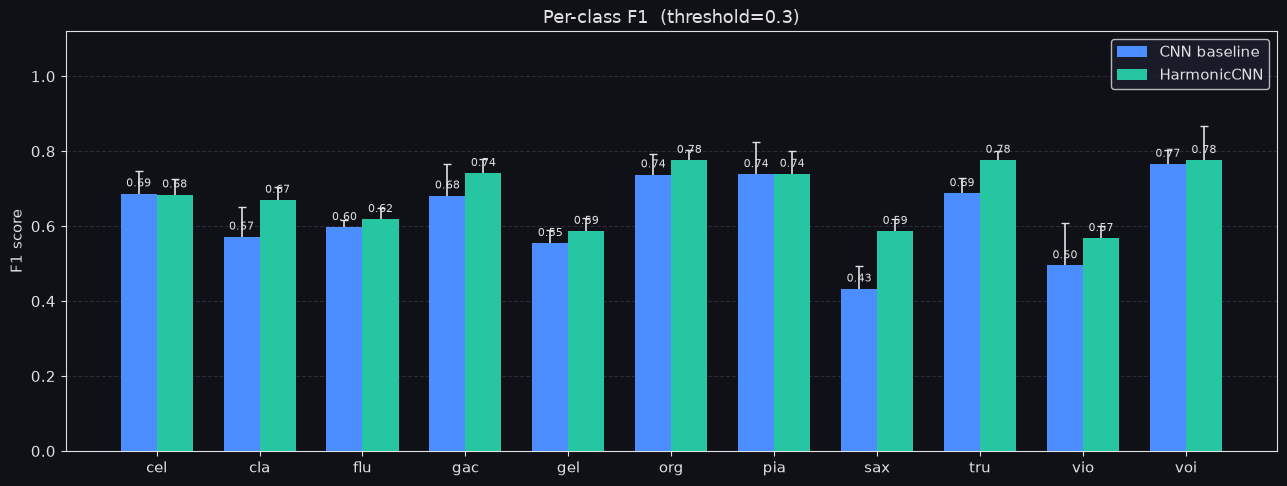

In [10]:
fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(CLASSES))
w = 0.35

b1 = ax.bar(x - w/2, cnn_r['f1_per'],  w, color=BLUE,  label='CNN baseline', zorder=3)
b2 = ax.bar(x + w/2, harm_r['f1_per'], w, color=GREEN, label='HarmonicCNN',   zorder=3)

if N_SEEDS > 1:
    ax.errorbar(x - w/2, cnn_r['f1_per'],  yerr=cnn_r['f1_per_std'],
                fmt='none', color=FG, capsize=3, lw=1.2)
    ax.errorbar(x + w/2, harm_r['f1_per'], yerr=harm_r['f1_per_std'],
                fmt='none', color=FG, capsize=3, lw=1.2)

for bar in list(b1) + list(b2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.012,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=8, color=FG)

ax.set_xticks(x)
ax.set_xticklabels(CLASSES)
ax.set_ylim(0, 1.12)
ax.set_ylabel('F1 score')
ax.set_title(f'Per-class F1  (threshold={THRESHOLD})', color=FG)
ax.legend(facecolor='#1e1e2e', edgecolor=FG)
ax.grid(axis='y', zorder=0)

plt.tight_layout()
plt.savefig('plots/harmonic_detail/h2_per_class_f1.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Plot — ΔF1 per class (HarmonicCNN − CNN)

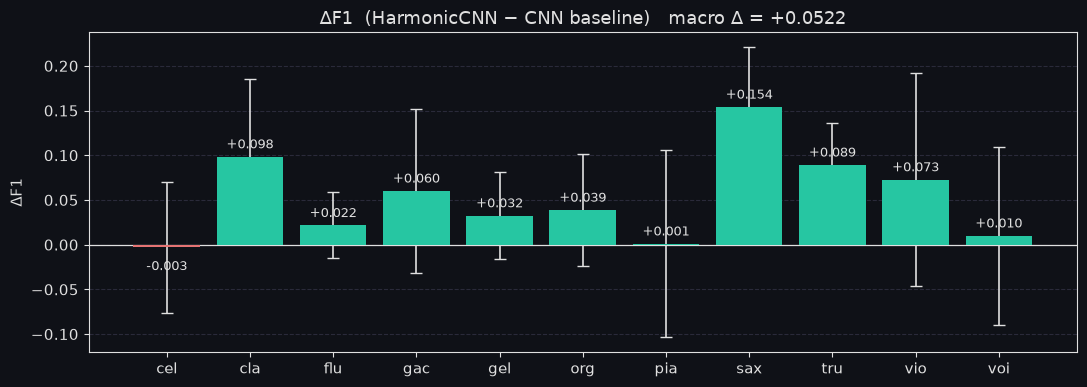

In [11]:
deltas = harm_r['f1_per'] - cnn_r['f1_per']
bar_colors = [GREEN if d >= 0 else RED for d in deltas]

fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.bar(CLASSES, deltas, color=bar_colors, zorder=3)

if N_SEEDS > 1:
    delta_std = np.sqrt(cnn_r['f1_per_std']**2 + harm_r['f1_per_std']**2)
    ax.errorbar(range(len(CLASSES)), deltas, yerr=delta_std,
                fmt='none', color=FG, capsize=4, lw=1.2)

ax.axhline(0, color=FG, lw=0.9)
for i, d in enumerate(deltas):
    ax.text(i, d + (0.006 if d >= 0 else -0.015),
            f'{d:+.3f}', ha='center',
            va='bottom' if d >= 0 else 'top', fontsize=9, color=FG)

macro_d = harm_r['f1_macro'] - cnn_r['f1_macro']
ax.set_title(f'ΔF1  (HarmonicCNN − CNN baseline)   macro Δ = {macro_d:+.4f}', color=FG)
ax.set_ylabel('ΔF1')
ax.grid(axis='y', zorder=0)

plt.tight_layout()
plt.savefig('plots/harmonic_detail/h3_delta_f1.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Plot — Precision / Recall / F1 per class

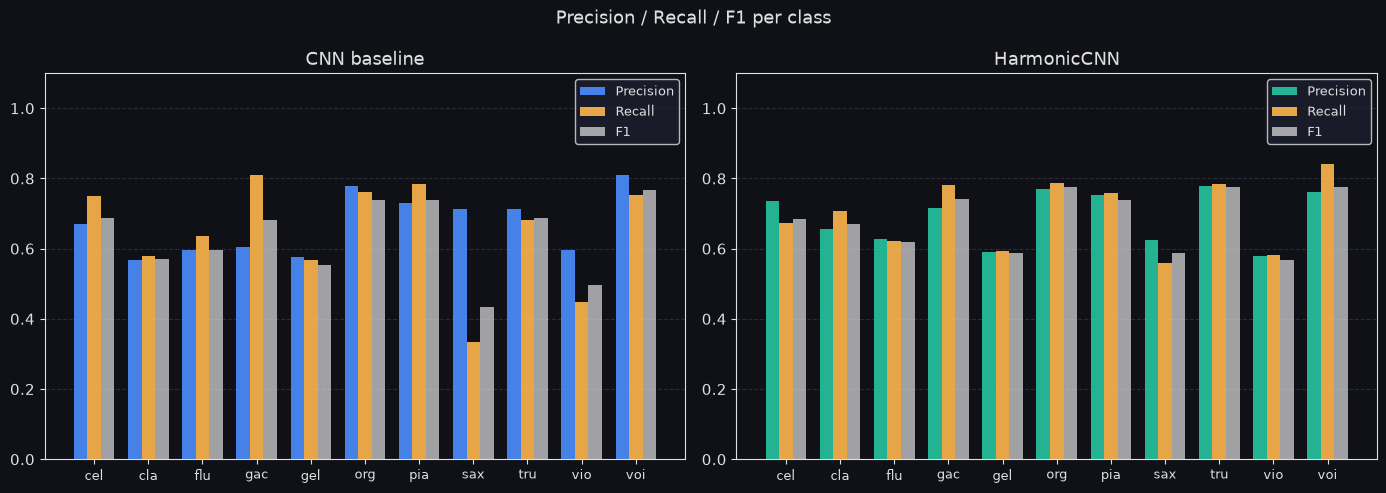

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Precision / Recall / F1 per class', color=FG, fontsize=13)

for ax, r, col, name in [
    (axes[0], cnn_r,  BLUE,  'CNN baseline'),
    (axes[1], harm_r, GREEN, 'HarmonicCNN'),
]:
    x = np.arange(len(CLASSES))
    w = 0.25
    ax.bar(x - w, r['prec_per'], w, color=col,    alpha=0.9, label='Precision', zorder=3)
    ax.bar(x,     r['rec_per'],  w, color=ORANGE,  alpha=0.9, label='Recall',    zorder=3)
    ax.bar(x + w, r['f1_per'],   w, color=FG,      alpha=0.7, label='F1',        zorder=3)
    ax.set_xticks(x)
    ax.set_xticklabels(CLASSES, fontsize=9)
    ax.set_ylim(0, 1.1)
    ax.set_title(name, color=FG)
    ax.legend(facecolor='#1e1e2e', edgecolor=FG, fontsize=9)
    ax.grid(axis='y', zorder=0)

plt.tight_layout()
plt.savefig('plots/harmonic_detail/h4_prec_rec_f1.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Plot — Average F1 by instrument family

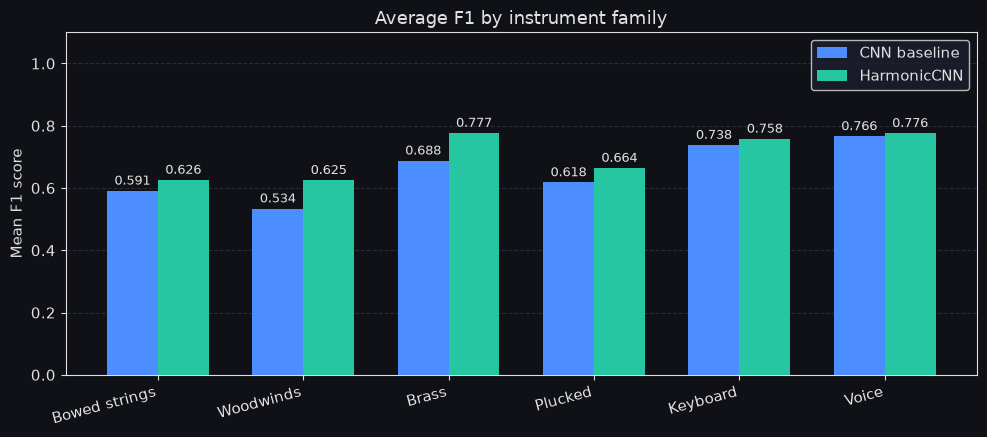

In [13]:
fam_names = list(FAMILIES.keys())
fam_cnn, fam_harm = [], []
for fam, clss in FAMILIES.items():
    idxs = [CLASSES.index(c) for c in clss]
    fam_cnn.append(float(np.mean([cnn_r['f1_per'][i]  for i in idxs])))
    fam_harm.append(float(np.mean([harm_r['f1_per'][i] for i in idxs])))

fig, ax = plt.subplots(figsize=(10, 4.5))
xf = np.arange(len(fam_names))
wf = 0.35

b1 = ax.bar(xf - wf/2, fam_cnn,  wf, color=BLUE,  label='CNN baseline', zorder=3)
b2 = ax.bar(xf + wf/2, fam_harm, wf, color=GREEN, label='HarmonicCNN',   zorder=3)

for bar in list(b1) + list(b2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9, color=FG)

ax.set_xticks(xf)
ax.set_xticklabels(fam_names, rotation=15, ha='right')
ax.set_ylim(0, 1.1)
ax.set_ylabel('Mean F1 score')
ax.set_title('Average F1 by instrument family', color=FG)
ax.legend(facecolor='#1e1e2e', edgecolor=FG)
ax.grid(axis='y', zorder=0)

plt.tight_layout()
plt.savefig('plots/harmonic_detail/h5_family_f1.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Save metrics to JSON

In [14]:
from datetime import datetime

out_dir = Path('plots/harmonic_detail')
out_dir.mkdir(parents=True, exist_ok=True)

data = {
    'meta': {
        'timestamp':     datetime.now().strftime('%Y-%m-%d %H:%M'),
        'epochs':        EPOCHS,
        'seeds':         N_SEEDS,
        'threshold':     THRESHOLD,
        'total_samples': total,
    },
    'CNN': {
        'params':           sum(p.numel() for p in InstrumentCNN().parameters() if p.requires_grad),
        'f1_macro_mean':    float(cnn_r['f1_macro']),
        'f1_macro_std':     float(cnn_r['f1_macro_std']),
        'f1_micro_mean':    float(cnn_r['f1_micro']),
        'f1_micro_std':     float(cnn_r['f1_micro_std']),
        'f1_macro_per_seed': [float(v) for v in cnn_r['f1_macro_all']],
        'per_class': {
            cls: {
                'f1':        float(cnn_r['f1_per'][i]),
                'f1_std':    float(cnn_r['f1_per_std'][i]),
                'precision': float(cnn_r['prec_per'][i]),
                'recall':    float(cnn_r['rec_per'][i]),
            }
            for i, cls in enumerate(CLASSES)
        },
    },
    'HarmonicCNN': {
        'params':           sum(p.numel() for p in HarmonicCNN().parameters() if p.requires_grad),
        'f1_macro_mean':    float(harm_r['f1_macro']),
        'f1_macro_std':     float(harm_r['f1_macro_std']),
        'f1_micro_mean':    float(harm_r['f1_micro']),
        'f1_micro_std':     float(harm_r['f1_micro_std']),
        'f1_macro_per_seed': [float(v) for v in harm_r['f1_macro_all']],
        'per_class': {
            cls: {
                'f1':        float(harm_r['f1_per'][i]),
                'f1_std':    float(harm_r['f1_per_std'][i]),
                'precision': float(harm_r['prec_per'][i]),
                'recall':    float(harm_r['rec_per'][i]),
            }
            for i, cls in enumerate(CLASSES)
        },
    },
    'delta': {
        'f1_macro': float(harm_r['f1_macro'] - cnn_r['f1_macro']),
        'f1_micro': float(harm_r['f1_micro'] - cnn_r['f1_micro']),
        'per_class': {
            cls: float(harm_r['f1_per'][i] - cnn_r['f1_per'][i])
            for i, cls in enumerate(CLASSES)
        },
    },
    'per_family': {
        fam: {
            'CNN':        float(np.mean([cnn_r['f1_per'][CLASSES.index(c)]  for c in clss])),
            'HarmonicCNN': float(np.mean([harm_r['f1_per'][CLASSES.index(c)] for c in clss])),
            'delta':      float(np.mean([harm_r['f1_per'][CLASSES.index(c)] - cnn_r['f1_per'][CLASSES.index(c)] for c in clss])),
        }
        for fam, clss in FAMILIES.items()
    },
}

json_path = out_dir / 'metrics.json'
with open(json_path, 'w') as f:
    json.dump(data, f, indent=2)

print(f'Saved: {json_path}')
print(json.dumps(data['delta'], indent=2))

Saved: plots/harmonic_detail/metrics.json
{
  "f1_macro": 0.05224181015378193,
  "f1_micro": 0.04432591829037735,
  "per_class": {
    "cel": -0.002819856861361103,
    "cla": 0.09834177523239807,
    "flu": 0.021541994809625042,
    "gac": 0.06003415414152291,
    "gel": 0.03240375058518885,
    "org": 0.03864348820816965,
    "pia": 0.0009029948173571167,
    "sax": 0.1539403643213786,
    "tru": 0.08913130915625955,
    "vio": 0.07267575558312578,
    "voi": 0.009864181697937457
  }
}


---
## 11. Evaluation on IRMAS Test Set (multi-label)

The official IRMAS test set contains **real polyphonic audio** where multiple instruments play simultaneously.
Each file has a companion `.txt` with the list of active instruments — true multi-label.

> **This is the fair comparison with published literature.**  
> Our validation set (20% of training) is single-label → easier.  
> The test set is multi-label → harder, lower absolute scores expected.

In [15]:
from dataset import load_testing_dataset

TEST_ROOT = PROJECT_ROOT / 'data' / 'IRMAS' / 'testing'

if not TEST_ROOT.exists():
    print("Test set not found. Run first:")
    print("  python src/download_data.py --include-test --max-per-class 400")
else:
    test_ds     = load_testing_dataset(TEST_ROOT)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    print(f"Test samples : {len(test_ds)}")
    print(f"(val samples : {len(val_ds)}  for reference)")

Test samples : 2874
(val samples : 878  for reference)


In [16]:
def eval_on_test(model_cls, model_name):
    """Average predictions across all seeds, evaluate on test set."""
    all_probs = []
    for seed in range(N_SEEDS):
        path = ckpt_path(model_name, seed)
        if not path.exists():
            print(f"  Missing checkpoint: {path.name} — run training cell first")
            return None
        ckpt  = torch.load(path, map_location=device, weights_only=False)
        model = model_cls().to(device)
        model.load_state_dict(ckpt['model_state'])
        raw = evaluate(model, test_loader)
        all_probs.append(raw['probs'])

    mean_probs = np.mean(all_probs, axis=0)
    targets    = raw['targets']
    preds      = (mean_probs >= THRESHOLD).astype(int)
    return compute_metrics(mean_probs, preds, targets)

print("Evaluating on IRMAS test set (multi-label)…")
test_cnn  = eval_on_test(InstrumentCNN, 'InstrumentCNN')
test_harm = eval_on_test(HarmonicCNN,   'HarmonicCNN')

if test_cnn and test_harm:
    print(f"\n{'Metric':<20} {'CNN baseline':>14} {'HarmonicCNN':>14} {'Δ':>8}")
    print("─" * 60)
    for label, key in [
        ("F1-macro",        "f1_macro"),
        ("F1-micro",        "f1_micro"),
        ("Precision-macro", "prec_macro"),
        ("Recall-macro",    "rec_macro"),
        ("Hamming Acc",     "hamming_acc"),
        ("Subset Acc",      "subset_acc"),
        ("AUC-ROC macro",   "auc_macro"),
    ]:
        cv, hv = test_cnn[key], test_harm[key]
        d = hv - cv
        sign = "▲" if d > 0 else "▼"
        print(f"{label:<20} {cv:>14.4f} {hv:>14.4f} {sign}{abs(d):.4f}")

Evaluating on IRMAS test set (multi-label)…



Metric                 CNN baseline    HarmonicCNN        Δ
────────────────────────────────────────────────────────────
F1-macro                     0.3669         0.4221 ▲0.0552
F1-micro                     0.4631         0.5131 ▲0.0499
Precision-macro              0.5356         0.5806 ▲0.0449
Recall-macro                 0.3029         0.3420 ▲0.0390
Hamming Acc                  0.8719         0.8828 ▲0.0109
Subset Acc                   0.2140         0.2505 ▲0.0365
AUC-ROC macro                0.7652         0.7816 ▲0.0164


In [112]:
import importlib, features
importlib.reload(features)
from features import compute_mel_windows

def eval_on_test_windowed(model_cls, model_name, hop_seconds=1.5):
    """Sliding-window inference: split each file into overlapping 3s windows,
    average probabilities across windows and seeds."""
    wav_paths = test_ds.wav_paths
    targets   = np.array(test_ds.labels)

    seed_file_probs = []

    for seed in range(N_SEEDS):
        path = ckpt_path(model_name, seed)
        if not path.exists():
            print(f"  Missing checkpoint: {path.name}")
            return None
        ckpt  = torch.load(path, map_location=device, weights_only=False)
        model = model_cls().to(device)
        model.load_state_dict(ckpt["model_state"])
        model.eval()

        file_probs = []
        with torch.no_grad():
            for wav in wav_paths:
                windows = compute_mel_windows(wav, hop_seconds=hop_seconds)
                batch = torch.tensor(
                    np.stack(windows)[:, None, :, :], dtype=torch.float32
                ).to(device)
                logits = model(batch)
                probs  = torch.sigmoid(logits).cpu().numpy()
                file_probs.append(probs.mean(axis=0))

        seed_file_probs.append(np.array(file_probs))

    mean_probs = np.mean(seed_file_probs, axis=0)
    preds      = (mean_probs >= THRESHOLD).astype(int)
    return compute_metrics(mean_probs, preds, targets)

print("Evaluating on IRMAS test set with sliding window (hop=1.5s)...")
test_cnn_win  = eval_on_test_windowed(InstrumentCNN, "InstrumentCNN")
test_harm_win = eval_on_test_windowed(HarmonicCNN,   "HarmonicCNN")

if test_cnn_win and test_harm_win:
    rows = [("F1-macro", "f1_macro"), ("F1-micro", "f1_micro"),
            ("Precision", "prec_macro"), ("Recall", "rec_macro"), ("AUC-ROC", "auc_macro")]
    print(f"\n{'Metric':<20} {'CNN crop':>10} {'CNN win':>10}    {'Harm crop':>10} {'Harm win':>10}")
    print("-" * 70)
    for label, key in rows:
        cc = test_cnn[key]  if test_cnn  else float("nan")
        cw = test_cnn_win[key]
        hc = test_harm[key] if test_harm else float("nan")
        hw = test_harm_win[key]
        delta_cnn  = cw - cc
        delta_harm = hw - hc
        print(f"{label:<20} {cc:>10.4f} {cw:>10.4f} ({delta_cnn:+.4f})  {hc:>10.4f} {hw:>10.4f} ({delta_harm:+.4f})")


Evaluating on IRMAS test set with sliding window (hop=1.5s)...



Metric                 CNN crop    CNN win     Harm crop   Harm win
----------------------------------------------------------------------
F1-macro                 0.3669     0.3833 (+0.0163)      0.4221     0.4573 (+0.0352)
F1-micro                 0.4631     0.4850 (+0.0219)      0.5131     0.5465 (+0.0335)
Precision                0.5356     0.5961 (+0.0605)      0.5806     0.6552 (+0.0746)
Recall                   0.3029     0.3045 (+0.0016)      0.3420     0.3601 (+0.0181)
AUC-ROC                  0.7652     0.7977 (+0.0324)      0.7816     0.8157 (+0.0341)


In [113]:
if test_cnn and test_harm:
    print(f"\n{'':30} {'Val (single-label)':>20} {'Test (multi-label)':>20}")
    print("─" * 72)
    for model_name, val_r, tst_r in [
        ('CNN baseline', cnn_r,  test_cnn),
        ('HarmonicCNN',  harm_r, test_harm),
    ]:
        vf = val_r['f1_macro']
        tf = tst_r['f1_macro']
        print(f"  {model_name:<28} F1-macro {vf:.4f}        F1-macro {tf:.4f}  (drop {vf-tf:.4f})")

    print(f"\n  Per-class F1 on TEST SET:")
    print(f"  {'Class':<6} {'Family':<16} {'CNN':>8} {'HarmCNN':>9} {'Δ':>7}")
    print("  " + "─" * 48)
    for i, cls in enumerate(CLASSES):
        cv = test_cnn['f1_per'][i]
        hv = test_harm['f1_per'][i]
        d  = hv - cv
        mark = '▲' if d > 0.005 else ('▼' if d < -0.005 else '=')
        print(f"  {cls:<6} {CLASS_TO_FAMILY[cls]:<16} {cv:>8.3f} {hv:>9.3f} {mark}{abs(d):.3f}")


                                 Val (single-label)   Test (multi-label)
────────────────────────────────────────────────────────────────────────
  CNN baseline                 F1-macro 0.6319        F1-macro 0.3669  (drop 0.2650)
  HarmonicCNN                  F1-macro 0.6841        F1-macro 0.4221  (drop 0.2620)

  Per-class F1 on TEST SET:
  Class  Family                CNN   HarmCNN       Δ
  ────────────────────────────────────────────────
  cel    Bowed strings       0.286     0.311 ▲0.026
  cla    Woodwinds           0.055     0.065 ▲0.010
  flu    Woodwinds           0.389     0.404 ▲0.016
  gac    Plucked             0.454     0.473 ▲0.019
  gel    Plucked             0.487     0.487 =0.001
  org    Keyboard            0.244     0.273 ▲0.030
  pia    Keyboard            0.399     0.400 =0.001
  sax    Woodwinds           0.457     0.546 ▲0.088
  tru    Brass               0.295     0.438 ▲0.143
  vio    Bowed strings       0.269     0.466 ▲0.198
  voi    Voice               0

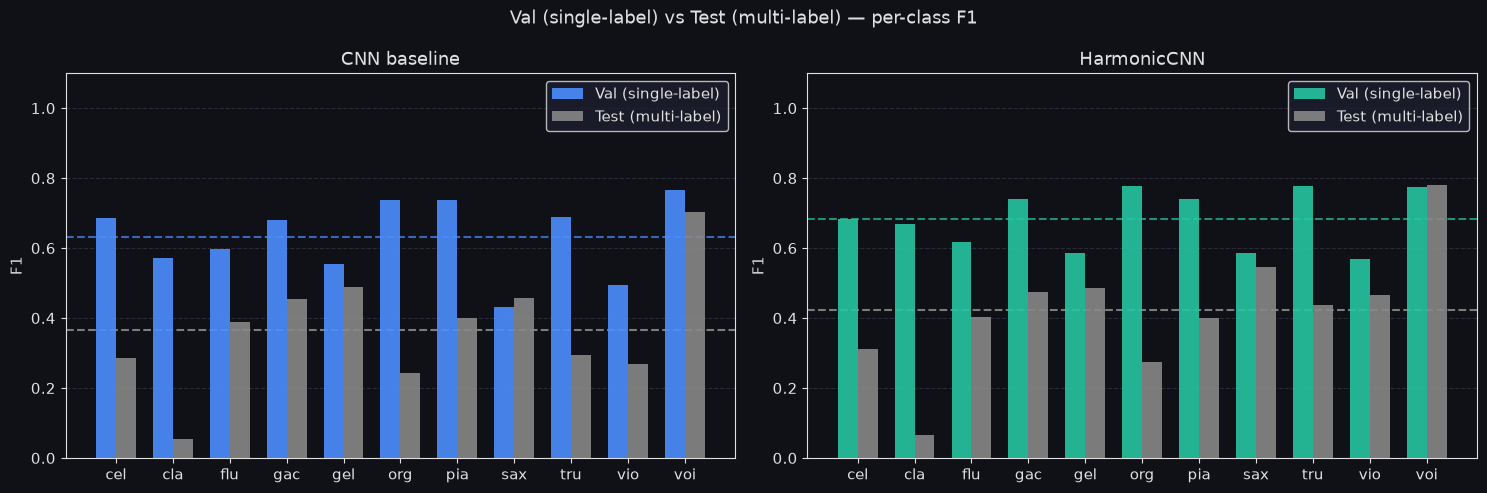

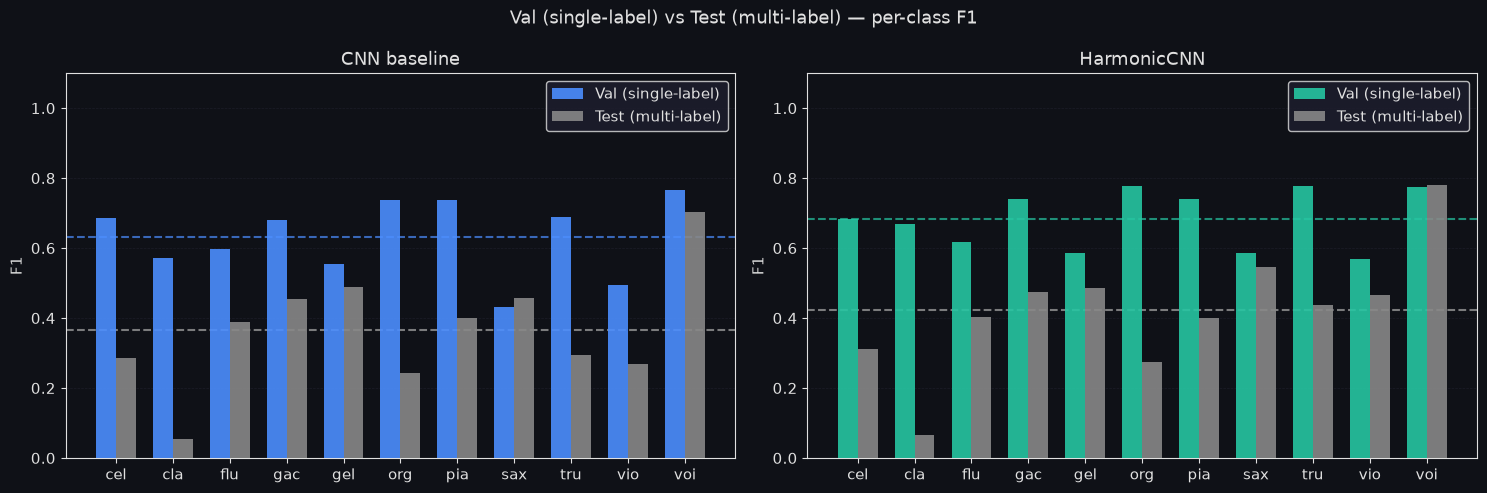

In [114]:
if test_cnn and test_harm:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    fig.suptitle('Val (single-label) vs Test (multi-label) — per-class F1', color=FG, fontsize=13)

    x = np.arange(len(CLASSES))
    w = 0.35

    for ax, val_r, tst_r, col, name in [
        (axes[0], cnn_r,  test_cnn,  BLUE,  'CNN baseline'),
        (axes[1], harm_r, test_harm, GREEN, 'HarmonicCNN'),
    ]:
        ax.bar(x - w/2, val_r['f1_per'], w, color=col,       alpha=0.9, label='Val (single-label)', zorder=3)
        ax.bar(x + w/2, tst_r['f1_per'], w, color='#888888', alpha=0.9, label='Test (multi-label)', zorder=3)
        ax.set_xticks(x)
        ax.set_xticklabels(CLASSES)
        ax.set_ylim(0, 1.1)
        ax.set_ylabel('F1')
        ax.set_title(name, color=FG)
        ax.legend(facecolor='#1e1e2e', edgecolor=FG)
        ax.grid(axis='y', zorder=0)
        ax.axhline(val_r['f1_macro'], color=col,       lw=1.5, linestyle='--', alpha=0.7)
        ax.axhline(tst_r['f1_macro'], color='#aaaaaa', lw=1.5, linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.savefig('plots/harmonic_detail/h8_val_vs_test.png', dpi=150, bbox_inches='tight')
    plt.show()